# 2. Preparación de los datos

**Proyecto:** Modelo predictivo de consumo de energía eléctrica residencial en Bogotá (TC1/TC2, SUI).
**Entrada:** `dataset_modelo_v4` (109.345.545 registros, 38 columnas), exportado de BigQuery a Parquet.
**Salida:** `dataset_modelo_prep`, conjunto limpio y listo para el modelado.

| Sección | Contenido |
|---|---|
| 0 | Librerías, parámetros y funciones |
| 1 | Carga de datos y muestra de exploración |
| 2 | Limpieza de registros |
| 3 | Eliminación de columnas |
| 4 | Valores atípicos en las características |
| 5 | Variables de calendario |
| 6 | Línea base y punto de control |
| 7 | Interrelación entre variables |
| 8 | Reducción y agrupación de variables |
| 9 | Conjunto final y exportación |
| 10 | Conclusiones |

## Principios estadísticos del notebook

1. **Ninguna relación se supone.** Toda afirmación sobre la relación entre variables se acompaña de una medida calculada aquí.
   Lo que no se mide se declara como *supuesto* y se lista en la sección 10.
2. **Tamaño del efecto antes que valor p.** Con cientos de miles de registros cualquier diferencia es «significativa»;
   las decisiones se basan en el tamaño del efecto, con convenciones declaradas:

   | Medida | Uso | Pequeño | Mediano | Grande |
   |---|---|---|---|---|
   | ρ de Spearman | numérica–numérica | 0,10 | 0,30 | 0,50 |
   | r rango-biserial (Mann–Whitney; positivo si el grupo a tiende a ser mayor) | dos grupos | 0,10 | 0,30 | 0,50 |
   | ε² (Kruskal–Wallis) | k grupos | 0,01 | 0,08 | 0,26 |
   | V de Cramér | categórica–categórica | 0,10 | 0,30 | 0,50 |

3. **Independencia.** Un usuario aparece hasta 48 meses. Las pruebas usan **un registro por usuario** para no violar el supuesto de independencia.
4. **Sin fuga de información en la selección.** Las decisiones que usan el objetivo (`KWH_DIA`) solo emplean registros hasta
   `ANIO_EXPLORACION_MAX` (2023). Esto obliga a que prueba y validación del modelado sean posteriores a 2023.
   La selección final de variables por relevancia predictiva se deja al modelado, dentro del conjunto de entrenamiento.
5. **Cuantiles exactos.** Los cuantiles aproximados de Dask no se usan: en la primera ejecución dieron cuartiles erróneos para
   `DIAS_FACTURADOS` (variable discreta). Se calculan con frecuencias exactas o con un histograma fino (resolución declarada).
6. **Umbrales declarados.** Los umbrales (Tukey, baja varianza, redundancia) son convenciones; se reporta la sensibilidad a su valor.

*Referencias de las convenciones (por incorporar a la bibliografía y verificar): Tukey (1977) para los límites de atípicos;
Kuhn y Johnson (2013) para variables de varianza casi nula; Cohen (1988) para tamaños de efecto; Tomczak y Tomczak (2014) para ε².*

## 0. Librerías, parámetros y funciones

In [1]:
import os
import glob
import shutil
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import dask.array as da
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from google.colab import drive

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.4f}'.format)
sns.set_theme(style='whitegrid')

Parámetros. Todo umbral se define aquí.

| Parámetro | Significado |
|---|---|
| `K_CANDIDATOS` | Factores del IQR evaluados para días facturados (1,5 = límite interior de Tukey; 3 = exterior) |
| `MAX_ELIM_MES` | Máximo % de registros que el filtro de días puede eliminar en cualquier mes del año (evita sesgo estacional) |
| `K_TUKEY_KWH` | Factor del IQR sobre `log(1 + KWH_DIA)` (3 = límite exterior de Tukey) |
| `NZV_RAZON`, `NZV_UNICOS` | Varianza casi nula: razón entre la 1.ª y 2.ª categoría más frecuentes y % de valores únicos |
| `UMBRAL_REDUNDANCIA` | \|ρ\| a partir del cual dos características se consideran redundantes |
| `UMBRAL_V_REDUNDANTE` | V de Cramér a partir de la cual una categórica es redundante con otra |
| `UMBRAL_BENCH_CEROS` | Proporción de línea base en cero que invalida un mes para evaluar la línea base |
| `PREFIJO_MUESTRA` | Prefijo del `NIU_USUARIO` (hash) para muestrear usuarios completos (~1/256) |
| `ANIO_EXPLORACION_MAX` | Último año usado en análisis que involucran el objetivo |

In [2]:
K_CANDIDATOS = [1.5, 2.0, 3.0]
MAX_ELIM_MES = 1.0
K_TUKEY_KWH = 3.0
NZV_RAZON, NZV_UNICOS = 95 / 5, 10
UMBRAL_REDUNDANCIA = 0.95
UMBRAL_V_REDUNDANTE = 0.5
UMBRAL_BENCH_CEROS = 0.5
PREFIJO_MUESTRA = '00'
ANIO_EXPLORACION_MAX = 2023
SEMILLA = 42

In [3]:
DRIVE_ORIGEN = '/content/drive/MyDrive/Superintendencia/dataset_modelo_v4'
LOCAL_ORIGEN = './dataset_modelo_v4'
LOCAL_CHECKPOINT = './dataset_prep_tmp'
DRIVE_SALIDA = '/content/drive/MyDrive/Superintendencia/dataset_modelo_prep'
DRIVE_FIGURAS = '/content/drive/MyDrive/Superintendencia/Distribución Datos/Preparación'

Funciones de apoyo: archivos y bitácora de registros.

In [4]:
def guardar_figura(fig, nombre):
    os.makedirs(DRIVE_FIGURAS, exist_ok=True)
    fig.savefig(os.path.join(DRIVE_FIGURAS, f'{nombre}.png'), dpi=150, bbox_inches='tight')

def copiar(ruta):
    destino = os.path.join(LOCAL_ORIGEN, os.path.basename(ruta))
    if not os.path.exists(destino):
        shutil.copy2(ruta, destino)

In [5]:
bitacora = []

def registrar(paso, ddf):
    n = len(ddf)
    bitacora.append({'paso': paso, 'registros': n})
    print(f'{paso}: {n:,} registros')

Funciones estadísticas: cuartiles, tamaños de efecto y muestreo de un registro por usuario.

In [6]:
def cuartiles_discretos(serie):
    frec = serie.value_counts().compute().sort_index()
    acum = frec.cumsum() / frec.sum()
    return acum.index[acum >= 0.25][0], acum.index[acum >= 0.75][0]

def cuartiles_histograma(conteo, bordes):
    acum = np.cumsum(conteo) / conteo.sum()
    return bordes[1:][np.searchsorted(acum, 0.25)], bordes[1:][np.searchsorted(acum, 0.75)]

def una_por_usuario(d):
    return d.groupby('NIU_USUARIO', observed=True).sample(1, random_state=SEMILLA).reset_index(drop=True)

In [7]:
def comparar_grupos(a, b):
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    return pd.Series({'n_a': len(a), 'n_b': len(b), 'mediana_a': np.median(a), 'mediana_b': np.median(b),
                      'p_valor': p, 'r_rango_biserial': 2 * u / (len(a) * len(b)) - 1})

In [8]:
def kruskal_epsilon(d, grupo, y='KWH_DIA'):
    grupos = [g[y].dropna().values for _, g in d.groupby(grupo, observed=True)]
    grupos = [g for g in grupos if len(g) > 1]
    n = sum(len(g) for g in grupos)
    if len(grupos) < 2:
        return pd.Series({'grupos': len(grupos), 'n': n, 'H': np.nan, 'p_valor': np.nan, 'epsilon2': np.nan})
    h, p = stats.kruskal(*grupos)
    return pd.Series({'grupos': len(grupos), 'n': n, 'H': h, 'p_valor': p, 'epsilon2': h / (n - 1)})

In [9]:
def cramer_v(tabla):
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

def spearman_ic(x, y):
    m = x.notna() & y.notna()
    rho, p = stats.spearmanr(x[m], y[m])
    n = m.sum(); se = 1.06 / np.sqrt(n - 3)
    lo, hi = np.tanh(np.arctanh(rho) + np.array([-1.96, 1.96]) * se)
    return pd.Series({'n': n, 'rho': rho, 'ic95_inf': lo, 'ic95_sup': hi, 'p_valor': p})

## 1. Carga de datos y muestra de exploración

In [10]:
drive.mount('/content/drive')
os.makedirs(LOCAL_ORIGEN, exist_ok=True)
archivos = glob.glob(os.path.join(DRIVE_ORIGEN, '*.parquet'))
print(f'Archivos en Drive: {len(archivos)}')

Mounted at /content/drive
Archivos en Drive: 1281


In [11]:
with ThreadPoolExecutor(max_workers=12) as ex:
    list(ex.map(copiar, archivos))
print('Copia local terminada')

Copia local terminada


In [12]:
df = dd.read_parquet(f'{LOCAL_ORIGEN}/*.parquet')
df['TIPO_MEDIDOR'] = df['TIPO_MEDIDOR'].replace({'ElectrÃ³nico': 'Electrónico',
                                                 'ElectromecÃ¡nico': 'Electromecánico'})
registrar('0. Conjunto original (v4)', df)

0. Conjunto original (v4): 109,345,545 registros


### 1.1 Muestra de exploración por usuarios
`NIU_USUARIO` es un hash hexadecimal; seleccionar los usuarios cuyo hash empieza por `PREFIJO_MUESTRA` equivale a un
muestreo pseudoaleatorio de usuarios completos (todos sus meses). Su representatividad se verifica con la distribución por estrato.

In [13]:
muestra_raw = df[df['NIU_USUARIO'].str.startswith(PREFIJO_MUESTRA)].compute().reset_index(drop=True)
muestra_raw['ANIO'] = pd.to_datetime(muestra_raw['PERIODO']).dt.year
print(f"Muestra: {len(muestra_raw):,} registros de {muestra_raw['NIU_USUARIO'].nunique():,} usuarios")

Muestra: 425,738 registros de 9,419 usuarios


In [14]:
pob = df['ESTRATO_SECTOR'].value_counts(normalize=True).compute().sort_index()
mue = muestra_raw['ESTRATO_SECTOR'].value_counts(normalize=True).sort_index()
pd.DataFrame({'población': pob, 'muestra': mue, 'diferencia (pp)': (mue - pob) * 100})

,población,muestra,diferencia (pp)
ESTRATO_SECTOR,,,
1,0.0764,0.0722,-0.4189
2,0.3400,0.3422,0.2184
3,0.3563,0.3569,0.0596
4,0.1440,0.1444,0.0399
5,0.0467,0.0471,0.0367
6,0.0365,0.0371,0.0643


**Análisis.** La muestra tiene 425.738 registros de 9.419 usuarios. La mayor diferencia absoluta por estrato entre muestra y población
es 0,42 puntos porcentuales (estrato 1); en los demás es ≤ 0,22 pp. La muestra reproduce la distribución por estrato.
**Límite:** solo se contrastó el estrato.

## 2. Limpieza de registros
Cada filtro se aplica por separado y se registra cuántos registros elimina.

### 2.1 Población objetivo: nivel de tensión 1 y sin autogeneración
**Criterio:** definición de la población de estudio (usuarios residenciales en nivel de tensión 1 que no autogeneran).
Es una decisión de alcance, no una inferencia de los datos. La prueba siguiente solo documenta si el consumo de los
grupos excluidos difiere del resto.

In [15]:
excluidos = df[(df['NIVEL_TENSION'] != 1) | (df['AUTOGENERADOR'] != 3)]
excluidos = excluidos[['NIU_USUARIO', 'KWH_DIA', 'NIVEL_TENSION', 'AUTOGENERADOR']].compute()
resto = muestra_raw.query('NIVEL_TENSION == 1 and AUTOGENERADOR == 3')

In [16]:
pd.DataFrame({
    'Nivel de tensión 2 vs. resto': comparar_grupos(
        una_por_usuario(excluidos.query('NIVEL_TENSION != 1'))['KWH_DIA'], una_por_usuario(resto)['KWH_DIA']),
    'Autogenerador vs. resto': comparar_grupos(
        una_por_usuario(excluidos.query('AUTOGENERADOR != 3'))['KWH_DIA'], una_por_usuario(resto)['KWH_DIA']),
}).T

,n_a,n_b,mediana_a,mediana_b,p_valor,r_rango_biserial
Nivel de tensión 2 vs. resto,16.0000,"9,419.0000",643.6607,3.4000,0.0000,0.9999
Autogenerador vs. resto,294.0000,"9,419.0000",7.1667,3.4000,0.0000,0.4652


**Análisis** (r positivo: el grupo *a* tiende a ser mayor).
- **Nivel de tensión 2:** 16 usuarios; mediana 643,7 kWh/día frente a 3,40 del resto; r = 1,00 (efecto grande).
- **Autogeneradores:** 294 usuarios; mediana 7,17 frente a 3,40 kWh/día; r = 0,47 (efecto mediano).

Ambos grupos consumen más que el resto. Es consistente con excluirlos, pero la exclusión es una decisión de alcance, no una conclusión
de la prueba. El grupo de nivel 2 es muy pequeño (n = 16).

In [17]:
df = df[(df['NIVEL_TENSION'] == 1) & (df['AUTOGENERADOR'] == 3)]
registrar('1. Nivel de tensión 1 y sin autogeneración', df)

1. Nivel de tensión 1 y sin autogeneración: 109,339,456 registros


### 2.2 Usuarios sin medidor
**Criterio:** la categoría `Usuario sin medidor` indica que no hay medición; el objetivo exige lectura real medida.

In [18]:
df = df[df['TIPO_MEDIDOR'] != 'Usuario sin medidor']
registrar('2. Con medidor', df)

2. Con medidor: 109,338,704 registros


### 2.3 Días facturados atípicos
**Criterio:** límites de Tukey $[Q_1 - k\,\mathrm{IQR},\; Q_3 + k\,\mathrm{IQR}]$ con cuartiles **exactos** (frecuencias de la variable discreta).
**Elección de $k$:** el menor valor de `K_CANDIDATOS` cuya eliminación no supere `MAX_ELIM_MES` % en ningún mes del año.
Así el filtro no elimina de forma desproporcionada los periodos de un mes concreto (sesgo estacional).

In [19]:
q1_d, q3_d = cuartiles_discretos(df['DIAS_FACTURADOS'])
iqr_d = q3_d - q1_d
lim_dias = {k: (q1_d - k * iqr_d, q3_d + k * iqr_d) for k in K_CANDIDATOS}
print(f'Q1 = {q1_d}, Q3 = {q3_d}, IQR = {iqr_d}')

Q1 = 29, Q3 = 32, IQR = 3


In [20]:
fuera = {k: ~df['DIAS_FACTURADOS'].between(lo, hi) for k, (lo, hi) in lim_dias.items()}
totales = dask.compute(*[f.sum() for f in fuera.values()])
por_mes = dask.compute(*[f.groupby(df['MES']).mean() for f in fuera.values()])
fuera_mes = pd.DataFrame(dict(zip(lim_dias, por_mes))).sort_index() * 100

In [21]:
pd.DataFrame({'mínimo': [v[0] for v in lim_dias.values()], 'máximo': [v[1] for v in lim_dias.values()],
              'registros fuera': totales, '% máximo en un mes': fuera_mes.max().values},
             index=pd.Index(lim_dias.keys(), name='k'))

,mínimo,máximo,registros fuera,% máximo en un mes
k,,,,
1.5000,24.5000,36.5000,55136,0.0678
2.0000,23.0000,38.0000,47222,0.0657
3.0000,20.0000,41.0000,36914,0.0615


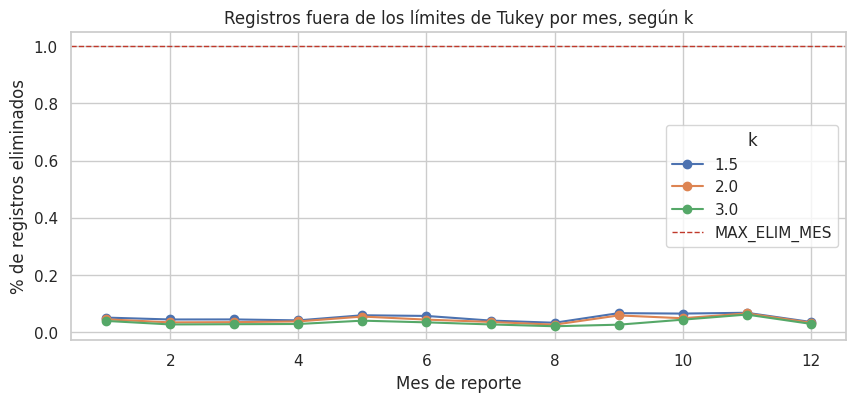

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
fuera_mes.plot(ax=ax, marker='o')
ax.axhline(MAX_ELIM_MES, color='#C0392B', ls='--', lw=1, label='MAX_ELIM_MES')
ax.set_xlabel('Mes de reporte'); ax.set_ylabel('% de registros eliminados')
ax.set_title('Registros fuera de los límites de Tukey por mes, según k'); ax.legend(title='k')
guardar_figura(fig, '01a_dias_eliminados_por_mes')
plt.show()

In [23]:
validos = [k for k in K_CANDIDATOS if fuera_mes[k].max() <= MAX_ELIM_MES]
K_TUKEY_DIAS = min(validos) if validos else max(K_CANDIDATOS)
DIAS_MIN, DIAS_MAX = lim_dias[K_TUKEY_DIAS]
print(f'k elegido: {K_TUKEY_DIAS}' + ('' if validos else ' (ningún k cumple el criterio: se usa el mayor)'))

k elegido: 1.5


**Análisis.** Con cuartiles exactos, $Q_1 = 29$ y $Q_3 = 32$ días (IQR = 3).

| k | Rango | Registros fuera | % máximo en un mes |
|---|---|---:|---:|
| 1,5 | [24,5; 36,5] | 55.136 | 0,068 % |
| 2,0 | [23; 38] | 47.222 | 0,066 % |
| 3,0 | [20; 41] | 36.914 | 0,062 % |

Con los tres valores de k la eliminación por mes queda entre 0,02 % y 0,07 %, muy por debajo de `MAX_ELIM_MES` (1 %), y sin
concentración en un mes (gráfica). Se elige k = 1,5. La diferencia con la ejecución anterior (11,5 millones eliminados con límites
[29, 37]) se debía a los cuartiles aproximados de Dask.

In [24]:
df = df[df['DIAS_FACTURADOS'].between(DIAS_MIN, DIAS_MAX)]
registrar(f'3. Días facturados en [{DIAS_MIN:.1f}, {DIAS_MAX:.1f}]', df)

3. Días facturados en [24.5, 36.5]: 109,283,568 registros


### 2.4 Consumo diario atípico en el objetivo
**Criterio:** límite superior de Tukey sobre $\log(1 + \text{KWH\_DIA})$ con $k$ = `K_TUKEY_KWH`.
Se usa la escala logarítmica porque la distribución tiene asimetría positiva (media = 4,62 kWh/día; máximo = 39.427 kWh/día)
y los límites de Tukey suponen una distribución aproximadamente simétrica.
No se aplica límite inferior: los ceros son lecturas reales.
Los cuartiles se obtienen de un histograma de 2.200 intervalos en $[0, 11]$ (resolución 0,005 en escala log).

In [25]:
conteo, bordes = da.histogram(np.log1p(df['KWH_DIA'].to_dask_array()), bins=2200, range=(0, 11))
conteo = conteo.compute()
q1_k, q3_k = cuartiles_histograma(conteo, bordes)
lim_kwh = {k: np.expm1(q3_k + k * (q3_k - q1_k)) for k in [1.5, 2.0, 3.0]}
UMBRAL_KWH_DIA = np.expm1(q3_k + K_TUKEY_KWH * (q3_k - q1_k))

In [26]:
fuera_kwh = dask.compute(*[(df['KWH_DIA'] > v).sum() for v in lim_kwh.values()])
print(f'Cuartiles de KWH_DIA: Q1 = {np.expm1(q1_k):.2f}, Q3 = {np.expm1(q3_k):.2f} kWh/día')
pd.DataFrame({'límite (kWh/día)': lim_kwh.values(), 'registros fuera': fuera_kwh},
             index=pd.Index(lim_kwh.keys(), name='k'))

Cuartiles de KWH_DIA: Q1 = 2.22, Q3 = 5.39 kWh/día


,límite (kWh/día),registros fuera
k,,
1.5000,16.8589,1762521
2.0000,24.1536,815591
3.0000,48.8990,262740


**Análisis.** Los cuartiles exactos (resolución 0,005 en escala log) de `KWH_DIA` son $Q_1$ = 2,22 y $Q_3$ = 5,39 kWh/día.
**Discrepancia:** el notebook 1 reportó $Q_1$ = 2,52 y $Q_3$ = 6,28 con cuantiles aproximados de Dask. El filtro de días solo eliminó
el 0,05 % de los registros, por lo que no explica la diferencia. Los cuartiles aproximados del notebook 1 se retiraron del trabajo de grado; los únicos cuartiles reportados son estos.

Con k = 3 el límite es 48,90 kWh/día (≈ 1.467 kWh/mes) y elimina 262.740 registros (0,24 %). Con k = 1,5 (16,9 kWh/día) se eliminarían
1.762.521 (1,6 %). En la gráfica, por encima de log(1 + x) ≈ 6 (≈ 400 kWh/día) la frecuencia deja de decrecer de forma continua y aparecen
registros aislados.

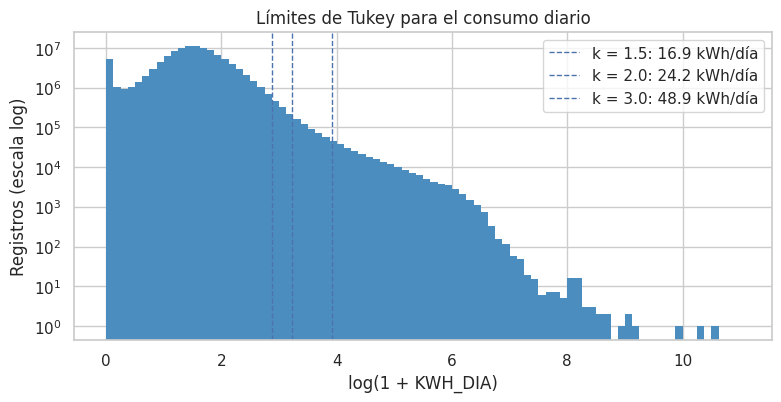

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.stairs(conteo.reshape(-1, 25).sum(axis=1), bordes[::25], fill=True, color='#4C8DBF')
for k, v in lim_kwh.items():
    ax.axvline(np.log1p(v), ls='--', lw=1, label=f'k = {k}: {v:.1f} kWh/día')
ax.set_yscale('log'); ax.set_xlabel('log(1 + KWH_DIA)'); ax.set_ylabel('Registros (escala log)')
ax.set_title('Límites de Tukey para el consumo diario'); ax.legend()
guardar_figura(fig, '01_limites_tukey_kwh')
plt.show()

In [28]:
df = df[df['KWH_DIA'] <= UMBRAL_KWH_DIA]
registrar(f'4. KWH_DIA <= {UMBRAL_KWH_DIA:.1f}', df)

4. KWH_DIA <= 48.9: 109,020,828 registros


### 2.5 Resumen de la limpieza de registros

In [29]:
tabla_limpieza = pd.DataFrame(bitacora)
tabla_limpieza['eliminados'] = -tabla_limpieza['registros'].diff().fillna(0).astype(int)
tabla_limpieza['% conservado'] = tabla_limpieza['registros'] / tabla_limpieza['registros'].iloc[0] * 100
tabla_limpieza

,paso,registros,eliminados,% conservado
0,0. Conjunto original (v4),109345545,0,100.0000
1,1. Nivel de tensión 1 y sin autogeneración,109339456,6089,99.9944
2,2. Con medidor,109338704,752,99.9937
3,"3. Días facturados en [24.5, 36.5]",109283568,55136,99.9433
4,4. KWH_DIA <= 48.9,109020828,262740,99.7030


**Análisis.** Se conservan 109.020.828 registros (99,70 %). El filtro que más elimina es el de consumo atípico (262.740), seguido del de
días facturados (55.136), autogeneración y nivel de tensión 2 (6.089) y usuarios sin medidor (752).

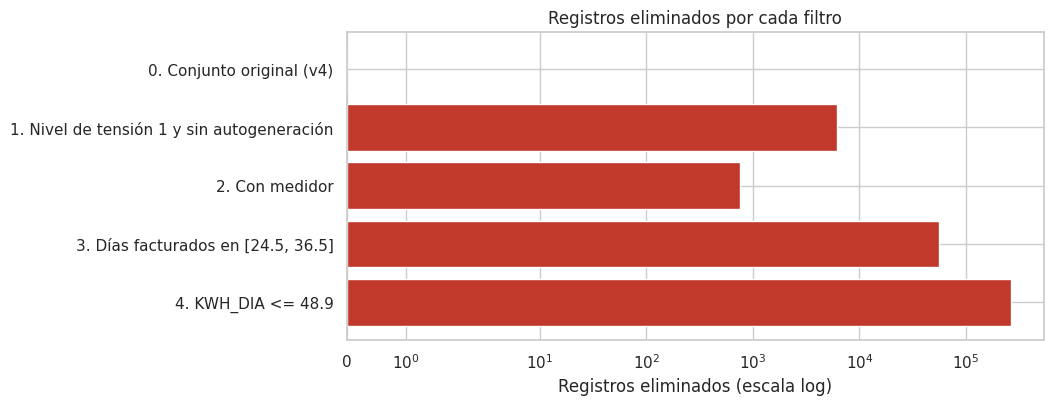

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tabla_limpieza['paso'][::-1], tabla_limpieza['eliminados'][::-1], color='#C0392B')
ax.set_xscale('symlog'); ax.set_xlabel('Registros eliminados (escala log)')
ax.set_title('Registros eliminados por cada filtro')
guardar_figura(fig, '02_registros_eliminados')
plt.show()

## 3. Eliminación de columnas

### 3.1 Varianza nula o casi nula
**Criterio (Kuhn y Johnson):** una variable tiene varianza casi nula si la razón entre su categoría más frecuente y la
segunda supera `NZV_RAZON` (19) y sus valores únicos son menos del `NZV_UNICOS` % de los registros.
- Varianza **nula** (un solo valor): se elimina.
- Varianza **casi nula**: no se elimina solo por eso; se mide su relación con el objetivo (sección 3.2).

In [31]:
cols_discretas = ['ID_MERCADO', 'DANE_NIU', 'TIPO_CONEXION', 'NIVEL_TENSION', 'AUTOGENERADOR', 'UBICACION',
                  'NRO_FAMILIAS', 'CAMBIO_TRAFO', 'CAMBIO_ESTRATO', 'CAMBIO_MEDIDOR', 'TIPO_MEDIDOR', 'ESTRATO_SECTOR']
conteos = dict(zip(cols_discretas, dask.compute(*[df[c].value_counts() for c in cols_discretas])))
n_actual = bitacora[-1]['registros']

In [32]:
def indicadores_nzv(s):
    s = s.sort_values(ascending=False)
    razon = s.iloc[0] / s.iloc[1] if len(s) > 1 else np.inf
    return pd.Series({'valores': len(s), '% dominante': s.iloc[0] / s.sum() * 100,
                      'razón 1.ª/2.ª': razon, '% únicos': len(s) / n_actual * 100})

tabla_nzv = pd.DataFrame({c: indicadores_nzv(s) for c, s in conteos.items()}).T
tabla_nzv['varianza'] = np.select([tabla_nzv['valores'] == 1,
                                   (tabla_nzv['razón 1.ª/2.ª'] > NZV_RAZON) & (tabla_nzv['% únicos'] < NZV_UNICOS)],
                                  ['nula', 'casi nula'], 'suficiente')
tabla_nzv

,valores,% dominante,razón 1.ª/2.ª,% únicos,varianza
ID_MERCADO,1.0000,100.0000,inf,0.0000,nula
DANE_NIU,1.0000,100.0000,inf,0.0000,nula
TIPO_CONEXION,1.0000,100.0000,inf,0.0000,nula
NIVEL_TENSION,1.0000,100.0000,inf,0.0000,nula
AUTOGENERADOR,1.0000,100.0000,inf,0.0000,nula
UBICACION,3.0000,99.3640,163.3278,0.0000,casi nula
NRO_FAMILIAS,10.0000,99.9988,"246,579.3395",0.0000,casi nula
CAMBIO_TRAFO,2.0000,99.9303,"1,433.7111",0.0000,casi nula
CAMBIO_ESTRATO,2.0000,99.9852,"6,743.2517",0.0000,casi nula
CAMBIO_MEDIDOR,2.0000,95.8470,23.0791,0.0000,casi nula


**Análisis.** Varianza nula: `ID_MERCADO`, `DANE_NIU`, `TIPO_CONEXION`, `NIVEL_TENSION`, `AUTOGENERADOR`.
Varianza casi nula: `UBICACION` (99,36 % en un valor), `NRO_FAMILIAS` (99,999 %), `CAMBIO_TRAFO` (99,93 %), `CAMBIO_ESTRATO` (99,99 %)
y `CAMBIO_MEDIDOR` (95,85 %; razón 23,1 > 19). `TIPO_MEDIDOR` y `ESTRATO_SECTOR` tienen varianza suficiente.

In [33]:
cols_varianza_nula = tabla_nzv.index[tabla_nzv['varianza'] == 'nula'].tolist()
cols_casi_nula = tabla_nzv.index[tabla_nzv['varianza'] == 'casi nula'].tolist()
print('Varianza nula (se eliminan):', cols_varianza_nula)
print('Varianza casi nula (se evalúan):', cols_casi_nula)

Varianza nula (se eliminan): ['ID_MERCADO', 'DANE_NIU', 'TIPO_CONEXION', 'NIVEL_TENSION', 'AUTOGENERADOR']
Varianza casi nula (se evalúan): ['UBICACION', 'NRO_FAMILIAS', 'CAMBIO_TRAFO', 'CAMBIO_ESTRATO', 'CAMBIO_MEDIDOR']


### 3.2 Relación con el objetivo de las variables de varianza casi nula
Se mide el tamaño del efecto (ε² de Kruskal–Wallis) sobre la muestra de exploración, con los mismos filtros de la sección 2: un registro por usuario, años ≤ `ANIO_EXPLORACION_MAX`.
**Criterio:** se eliminan si ε² < 0,01 (efecto menor que pequeño). Si el efecto es mayor, se conservan aunque su varianza sea baja.

In [34]:
filtros_seccion_2 = ('NIVEL_TENSION == 1 and AUTOGENERADOR == 3 and TIPO_MEDIDOR != "Usuario sin medidor"'
                     ' and @DIAS_MIN <= DIAS_FACTURADOS <= @DIAS_MAX and KWH_DIA <= @UMBRAL_KWH_DIA')
exploracion = muestra_raw.query(filtros_seccion_2).query('ANIO <= @ANIO_EXPLORACION_MAX')
exploracion = una_por_usuario(exploracion)
print(f'Registros de exploración (uno por usuario): {len(exploracion):,}')

Registros de exploración (uno por usuario): 8,876


In [35]:
efecto_nzv = pd.DataFrame({c: kruskal_epsilon(exploracion, c) for c in cols_casi_nula
                           if exploracion[c].nunique() > 1}).T
efecto_nzv

,grupos,n,H,p_valor,epsilon2
UBICACION,2.0000,"8,875.0000",9.7660,0.0018,0.0011
CAMBIO_TRAFO,1.0000,"8,875.0000",NaN,NaN,NaN
CAMBIO_MEDIDOR,2.0000,"8,876.0000",0.2499,0.6171,0.0000


In [36]:
no_estimable = efecto_nzv.index[efecto_nzv['epsilon2'].isna()].tolist()
cols_nzv_sin_efecto = efecto_nzv.index[efecto_nzv['epsilon2'] < 0.01].tolist() + no_estimable
cols_nzv_sin_efecto += [c for c in cols_casi_nula if c not in efecto_nzv.index]
print('Efecto no estimable (menos de 2 grupos con n > 1):', no_estimable)
print('Casi nula y sin efecto (se eliminan):', cols_nzv_sin_efecto)

Efecto no estimable (menos de 2 grupos con n > 1): ['CAMBIO_TRAFO']
Casi nula y sin efecto (se eliminan): ['UBICACION', 'CAMBIO_MEDIDOR', 'CAMBIO_TRAFO', 'NRO_FAMILIAS', 'CAMBIO_ESTRATO']


**Análisis** (8.876 usuarios, un registro cada uno, años ≤ 2023).
- `UBICACION`: ε² = 0,0011 (p = 0,002); `CAMBIO_MEDIDOR`: ε² = 0,0000 (p = 0,62). Ambas por debajo de un efecto pequeño.
  `UBICACION` es significativa pero con efecto despreciable: la decisión se toma por tamaño del efecto.
- `CAMBIO_TRAFO` y `CAMBIO_ESTRATO`: no estimables (un solo grupo con más de una observación en la muestra).
- `NRO_FAMILIAS`: sin variación en la muestra.

Las cinco se eliminan.

### 3.3 `CONS_SUBSIST` frente al estrato
**Criterio:** si la V de Cramér entre `CONS_SUBSIST` y `ESTRATO_SECTOR` es ≥ `UMBRAL_V_REDUNDANTE`, la primera es redundante.
Además se mide si los registros cuya etiqueta no coincide con su estrato tienen un consumo distinto.

In [37]:
tabla_subsist = df.groupby(['ESTRATO_SECTOR', 'CONS_SUBSIST']).size().compute().unstack(fill_value=0)
tabla_subsist.columns = [c[:40] for c in tabla_subsist.columns]
print(f'V de Cramér: {cramer_v(tabla_subsist):.3f}')
tabla_subsist

V de Cramér: 0.683


,130 kWh mes para alturas iguales o super,173 kWh mes para alturas inferiores a 1.,Cuando se refiera a usuarios de estratos
ESTRATO_SECTOR,,,
1,8250817,264,90936
2,36616698,1291,504575
3,38111030,2041,751130
4,11400,4,15660400
5,4,1,5079816
6,30,50,3940341


In [38]:
e13 = exploracion[exploracion['ESTRATO_SECTOR'] <= 3]
etiqueta_456 = e13['CONS_SUBSIST'].str.startswith('Cuando se refiera')
comparar_grupos(e13.loc[etiqueta_456, 'KWH_DIA'], e13.loc[~etiqueta_456, 'KWH_DIA']).to_frame(
    'Estratos 1–3: etiqueta «4, 5, 6» (a) vs. otras (b)')

,"Estratos 1–3: etiqueta «4, 5, 6» (a) vs. otras (b)"
n_a,50.0000
n_b,"6,811.0000"
mediana_a,2.7801
mediana_b,3.5484
p_valor,0.0415
r_rango_biserial,-0.1671


**Análisis.** V de Cramér entre `CONS_SUBSIST` y el estrato = 0,683 (≥ 0,5): la columna es redundante y se elimina.

Hallazgo de calidad (población limpia):
- 1.346.641 registros de estratos 1–3 tienen la etiqueta «estratos 4, 5, 6 y no residenciales».
- 3.596 registros de estratos 1–3 tienen «173 kWh/mes para alturas inferiores a 1.000 m», que no corresponde a la altitud de Bogotá.
- En la muestra, los 50 usuarios de estratos 1–3 con la etiqueta «4, 5, 6» tienen mediana 2,78 kWh/día frente a 3,55 del resto
  (r = −0,17, efecto pequeño; p = 0,042; n reducido).

La causa no se puede determinar con estos datos; se reporta para revisarla con el comercializador.

**Decisión:** se elimina si V ≥ `UMBRAL_V_REDUNDANTE`. Si el efecto de la etiqueta inconsistente sobre el consumo es al menos
pequeño (|r| ≥ 0,1), la inconsistencia se reporta como hallazgo de calidad para revisarla con el comercializador.

In [39]:
cols_redundantes = ['CONS_SUBSIST'] if cramer_v(tabla_subsist) >= UMBRAL_V_REDUNDANTE else []
cols_redundantes

['CONS_SUBSIST']

### 3.4 Variables con fuga de información
**Criterio (por definición, no por datos):**
- `CONSUMO_KWH`: el objetivo se calcula como `CONSUMO_KWH / DIAS_FACTURADOS`.
- `ENE_EXPORT`, `CONS_RECUP`, `DIAS_MORA`: se reportan en la misma factura del periodo que se quiere predecir,
  por lo que no están disponibles antes de la lectura.

In [40]:
cols_fuga = ['CONSUMO_KWH', 'ENE_EXPORT', 'CONS_RECUP', 'DIAS_MORA']

### 3.5 Estabilidad de `TIPO_MEDIDOR`
`CAMBIO_MEDIDOR` y `MESES_DESDE_CAMBIO` dependen de que `TIPO_MEDIDOR` cambie solo cuando se cambia el medidor.
**Prueba:** en la muestra de usuarios (todos los años, sin usar el objetivo) se cuentan los cambios entre registros consecutivos
y cuántos de ellos se revierten en el registro siguiente (patrón A → B → A).
**Criterio:** si más del 50 % de los cambios se revierten, la variable no mide cambios físicos y ambas columnas se eliminan.

In [41]:
serie = muestra_raw.sort_values(['NIU_USUARIO', 'PERIODO'])
g = serie.groupby('NIU_USUARIO')['TIPO_MEDIDOR']
ant1, ant2 = g.shift(1), g.shift(2)
cambio = ant1.notna() & (serie['TIPO_MEDIDOR'] != ant1)
reversion = cambio.shift(1, fill_value=False) & (serie['TIPO_MEDIDOR'] == ant2) & (serie['TIPO_MEDIDOR'] != ant1)

In [42]:
n_cambios, n_rev = int(cambio.sum()), int(reversion.sum())
pd.Series({'% registros con cambio': cambio.mean() * 100, 'cambios': n_cambios,
           'reversiones A→B→A': n_rev, '% de cambios revertidos': n_rev / max(n_cambios, 1) * 100})

,0
% registros con cambio,2.1748
cambios,"9,259.0000"
reversiones A→B→A,14.0000
% de cambios revertidos,0.1512


**Análisis. Se rechaza la hipótesis de que `TIPO_MEDIDOR` oscila.** El 2,17 % de los registros consecutivos cambia de tipo de medidor
(9.259 cambios), pero solo 14 (0,15 %) se revierten al registro siguiente (A → B → A): los cambios son persistentes.
La causa de los cambios no se puede identificar con estos datos. Limitaciones: la muestra solo tiene lecturas reales y el desplazamiento
es por registro, no por mes. `MESES_DESDE_CAMBIO` se conserva.

In [43]:
cols_no_confiables = ['CAMBIO_MEDIDOR', 'MESES_DESDE_CAMBIO'] if n_rev / max(n_cambios, 1) > 0.5 else []
cols_no_confiables

[]

### 3.6 Resumen y eliminación

In [44]:
grupos = {'Varianza nula': cols_varianza_nula, 'Varianza casi nula sin efecto': cols_nzv_sin_efecto,
          'Redundante': cols_redundantes, 'Fuga de información': cols_fuga, 'No confiable': cols_no_confiables}
resumen_cols = pd.DataFrame([(m, c) for m, cs in grupos.items() for c in cs], columns=['motivo', 'columna'])
resumen_cols = resumen_cols.drop_duplicates('columna')
resumen_cols

,motivo,columna
0,Varianza nula,ID_MERCADO
1,Varianza nula,DANE_NIU
2,Varianza nula,TIPO_CONEXION
3,Varianza nula,NIVEL_TENSION
4,Varianza nula,AUTOGENERADOR
5,Varianza casi nula sin efecto,UBICACION
6,Varianza casi nula sin efecto,CAMBIO_MEDIDOR
7,Varianza casi nula sin efecto,CAMBIO_TRAFO
8,Varianza casi nula sin efecto,NRO_FAMILIAS
9,Varianza casi nula sin efecto,CAMBIO_ESTRATO


In [45]:
df = df.drop(columns=resumen_cols['columna'].tolist())
print(f'Columnas restantes ({len(df.columns)}):', list(df.columns))

Columnas restantes (23): ['PERIODO', 'MES', 'NIU_USUARIO', 'COD_CIRCUITO_LINEA', 'COD_TRANSFORMADOR', 'ESTRATO_SECTOR', 'TIPO_MEDIDOR', 'DIAS_FACTURADOS', 'PROM_SEM_BENCHMARK', 'FECHA_LECTURA', 'FECHA_FACTURA', 'KWH_DIA', 'KWH_DIA_LAG1', 'KWH_DIA_LAG2', 'KWH_DIA_LAG3', 'KWH_DIA_LAG12', 'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_STD6', 'KWH_DIA_MM12', 'PCT_CEROS_PREVIOS', 'MESES_HIST_12', 'MESES_DESDE_CAMBIO']


## 4. Valores atípicos en las características
Los rezagos y medias móviles se calcularon en BigQuery antes del filtro de lectura real (*004.6 Consulta dataset_modelo_v4*).
**Criterio:** se aplica el mismo límite del objetivo (`UMBRAL_KWH_DIA`, sección 2.4), porque son la misma magnitud
(kWh/día) en meses anteriores. Los valores que lo superan pasan a nulo (no se elimina el registro, porque su objetivo es válido).

In [46]:
cols_consumo = ['KWH_DIA_LAG1', 'KWH_DIA_LAG2', 'KWH_DIA_LAG3', 'KWH_DIA_LAG12',
                'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_MM12']
n_extremos = dask.compute(*[(df[c] > UMBRAL_KWH_DIA).sum() for c in cols_consumo])
pd.Series(n_extremos, index=cols_consumo, name='valores > umbral')

,valores > umbral
KWH_DIA_LAG1,23525
KWH_DIA_LAG2,25718
KWH_DIA_LAG3,27895
KWH_DIA_LAG12,30924
KWH_DIA_MM3,22399
KWH_DIA_MM6,22028
KWH_DIA_MM12,23279


**Análisis.** Entre 22.028 y 30.924 valores por característica superan 48,90 kWh/día (≈ 0,02–0,03 % de los registros) y pasan a nulo.

In [47]:
for c in cols_consumo:
    df[c] = df[c].where(df[c] <= UMBRAL_KWH_DIA)
df['KWH_DIA_STD6'] = df['KWH_DIA_STD6'].where(df['KWH_DIA_MM6'].notnull())

## 5. Variables de calendario
`PERIODO` es el mes de **reporte**. Por definición de los campos de TC2, el consumo facturado corresponde a los
`DIAS_FACTURADOS` anteriores a `FECHA_LECTURA`.

**Supuesto (no verificable con estos datos):** la fecha real de lectura se usa como aproximación de la fecha planeada
del cronograma de lectura, que sí se conoce antes de leer. Debe validarse con el comercializador.
`FECHA_FACTURA` es posterior a la lectura; solo se usa para calcular el retraso de facturación.

In [48]:
df['F_LECTURA'] = dd.to_datetime(df['FECHA_LECTURA'], format='%d/%m/%y', errors='coerce')
df['F_FACTURA'] = dd.to_datetime(df['FECHA_FACTURA'], format='%d/%m/%y', errors='coerce')

### 5.1 Validación de las fechas

In [49]:
chequeos = dask.compute(df['F_LECTURA'].isnull().mean(), df['F_FACTURA'].isnull().mean(),
                        (df['F_FACTURA'] < df['F_LECTURA']).mean(),
                        df['F_LECTURA'].min(), df['F_LECTURA'].max())
pd.Series(chequeos, index=['% lectura no convertible', '% factura no convertible',
                           '% factura antes de lectura', 'lectura mínima', 'lectura máxima'])

,0
% lectura no convertible,0.0000
% factura no convertible,0.0000
% factura antes de lectura,0.0000
lectura mínima,2021-12-28 00:00:00
lectura máxima,2025-12-31 00:00:00


**Análisis.** Todas las fechas se convierten, ninguna factura es anterior a su lectura y las lecturas van del 28/12/2021 al 31/12/2025.

### 5.2 Variables derivadas
| Variable | Definición |
|---|---|
| `DIA_LECTURA` | Día del mes de `FECHA_LECTURA` |
| `MES_CONSUMO` | Mes de `FECHA_LECTURA − DIAS_FACTURADOS / 2` (punto medio de la ventana) |
| `DIAS_FIN_SEMANA` | Sábados y domingos en la ventana `[lectura − días, lectura)` |
| `DIAS_FESTIVOS` | Festivos de Colombia en días hábiles de la ventana (librería `holidays`) |
| `RETRASO_FACTURA` | `FECHA_FACTURA − FECHA_LECTURA`, en días |

In [50]:
df['DIA_LECTURA'] = df['F_LECTURA'].dt.day
medio = df['F_LECTURA'] - dd.to_timedelta(df['DIAS_FACTURADOS'] / 2, unit='D')
df['MES_CONSUMO'] = medio.dt.month
df['RETRASO_FACTURA'] = (df['F_FACTURA'] - df['F_LECTURA']).dt.days

In [51]:
FESTIVOS = np.array(sorted(holidays.Colombia(years=range(2021, 2026))), dtype='datetime64[D]')

def contar_dias(p):
    fin = p['F_LECTURA'].values.astype('datetime64[D]')
    ini = fin - p['DIAS_FACTURADOS'].values.astype('timedelta64[D]')
    ok = ~np.isnat(fin)
    lab = np.full(len(p), np.nan); hab = np.full(len(p), np.nan)
    lab[ok] = np.busday_count(ini[ok], fin[ok])
    hab[ok] = np.busday_count(ini[ok], fin[ok], holidays=FESTIVOS)
    return p.assign(DIAS_FIN_SEMANA=p['DIAS_FACTURADOS'] - lab, DIAS_FESTIVOS=lab - hab)

In [52]:
meta = df._meta.assign(DIAS_FIN_SEMANA=np.float64(), DIAS_FESTIVOS=np.float64())
df = df.map_partitions(contar_dias, meta=meta)
df = df.drop(columns=['FECHA_LECTURA', 'FECHA_FACTURA', 'F_LECTURA', 'F_FACTURA'])
cols_calendario = ['DIA_LECTURA', 'DIAS_FIN_SEMANA', 'DIAS_FESTIVOS', 'RETRASO_FACTURA']

## 6. Línea base y punto de control

### 6.1 Meses con línea base inválida
**Criterio:** un mes se marca como inválido para evaluar la línea base si más del `UMBRAL_BENCH_CEROS` de sus registros
tiene `PROM_SEM_BENCHMARK = 0`. El registro se conserva para el entrenamiento, porque su objetivo es válido.

In [53]:
periodo_txt = df['PERIODO'].astype(str)
ceros_mes = (df['PROM_SEM_BENCHMARK'] == 0).groupby(periodo_txt).mean().compute().sort_index()
PERIODOS_BENCH_INVALIDOS = ceros_mes[ceros_mes > UMBRAL_BENCH_CEROS].index.tolist()
print('Meses inválidos:', PERIODOS_BENCH_INVALIDOS)

Meses inválidos: ['2023-09-01']


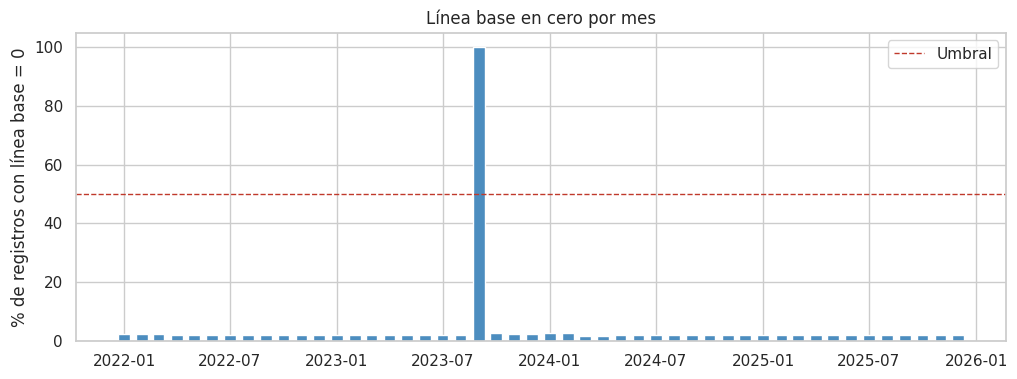

In [54]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(pd.to_datetime(ceros_mes.index), ceros_mes.values * 100, width=20, color='#4C8DBF')
ax.axhline(UMBRAL_BENCH_CEROS * 100, color='#C0392B', ls='--', lw=1, label='Umbral')
ax.set_ylabel('% de registros con línea base = 0'); ax.set_title('Línea base en cero por mes')
ax.legend()
guardar_figura(fig, '03_linea_base_ceros')
plt.show()

**Análisis.** Solo septiembre de 2023 supera el 50 % de registros con línea base en cero; es el único mes con `BENCH_VALIDO = 0`.

In [55]:
df['BENCH_KWH_DIA'] = df['PROM_SEM_BENCHMARK'] / df['DIAS_FACTURADOS']
df['BENCH_VALIDO'] = (~periodo_txt.isin(PERIODOS_BENCH_INVALIDOS)).astype('int8')

### 6.2 Punto de control
Dask acumula las operaciones sin ejecutarlas. Se guarda el resultado en disco local y se vuelve a leer para que las
secciones siguientes no repitan toda la preparación (en la primera ejecución, tomar la muestra sin este paso agotó la conexión con Colab).

Las columnas enteras sin nulos se fijan como enteros (en la ejecución anterior quedaron como `float64`).

In [56]:
enteros = {'MES': 'int8', 'ESTRATO_SECTOR': 'int8', 'DIAS_FACTURADOS': 'int16', 'MESES_HIST_12': 'int8',
           'MES_CONSUMO': 'int8', 'DIA_LECTURA': 'int8'}
df = df.astype(enteros)

In [57]:
df.to_parquet(LOCAL_CHECKPOINT, write_index=False, overwrite=True)
df = dd.read_parquet(LOCAL_CHECKPOINT)
registrar('5. Punto de control', df)
df.dtypes

5. Punto de control: 109,020,828 registros


,0
PERIODO,date32[day][pyarrow]
MES,int8
NIU_USUARIO,string[pyarrow]
COD_CIRCUITO_LINEA,string[pyarrow]
COD_TRANSFORMADOR,string[pyarrow]
ESTRATO_SECTOR,int8
TIPO_MEDIDOR,string[pyarrow]
DIAS_FACTURADOS,int16
PROM_SEM_BENCHMARK,float64
KWH_DIA,float64


**Análisis.** Punto de control: 109.020.828 registros. Los tipos enteros quedaron correctos; `MESES_DESDE_CAMBIO` sigue como `float64`
porque tiene nulos.

## 7. Interrelación entre variables
Se usan los mismos usuarios de la muestra de exploración, ya preparados, con años ≤ `ANIO_EXPLORACION_MAX`.
- `muestra`: todos los meses de esos usuarios (gráficas descriptivas).
- `indep`: un registro por usuario (medidas de asociación e intervalos de confianza).

In [58]:
anio = dd.to_datetime(df['PERIODO']).dt.year
muestra = df[df['NIU_USUARIO'].str.startswith(PREFIJO_MUESTRA) & (anio <= ANIO_EXPLORACION_MAX)].compute().reset_index(drop=True)
indep = una_por_usuario(muestra)
print(f'muestra: {len(muestra):,} registros | indep: {len(indep):,} usuarios')

muestra: 208,211 registros | indep: 8,876 usuarios


### 7.1 Correlación de Spearman entre variables numéricas (un registro por usuario)

In [59]:
cols_num = ['KWH_DIA', 'BENCH_KWH_DIA'] + cols_consumo + \
           ['KWH_DIA_STD6', 'PCT_CEROS_PREVIOS', 'MESES_HIST_12', 'DIAS_FACTURADOS'] + cols_calendario
corr = indep[cols_num].corr(method='spearman')

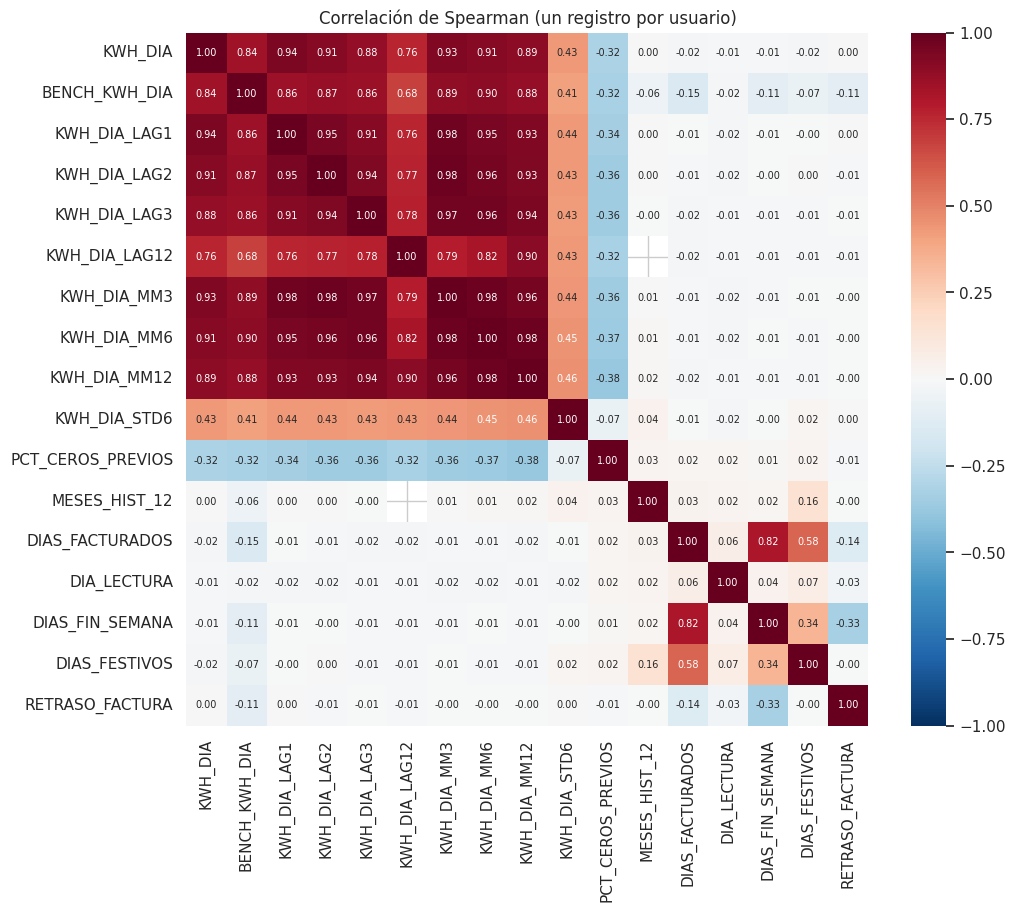

In [60]:
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 7})
ax.set_title('Correlación de Spearman (un registro por usuario)')
guardar_figura(fig, '04_correlacion_spearman')
plt.show()

### 7.2 Asociación de cada variable numérica con el objetivo (ρ e IC 95 %)

In [61]:
asoc_num = pd.DataFrame({c: spearman_ic(indep[c], indep['KWH_DIA']) for c in cols_num if c != 'KWH_DIA'}).T
asoc_num = asoc_num.sort_values('rho')
asoc_num

,n,rho,ic95_inf,ic95_sup,p_valor
PCT_CEROS_PREVIOS,"8,439.0000",-0.3155,-0.3357,-0.2950,0.0000
DIAS_FESTIVOS,"8,876.0000",-0.0184,-0.0404,0.0037,0.0830
DIAS_FACTURADOS,"8,876.0000",-0.0183,-0.0403,0.0038,0.0852
DIA_LECTURA,"8,876.0000",-0.0129,-0.0349,0.0092,0.2254
DIAS_FIN_SEMANA,"8,876.0000",-0.0113,-0.0333,0.0108,0.2880
RETRASO_FACTURA,"8,876.0000",0.0010,-0.0210,0.0231,0.9245
MESES_HIST_12,"8,876.0000",0.0010,-0.0210,0.0231,0.9212
KWH_DIA_STD6,"8,037.0000",0.4333,0.4143,0.4519,0.0000
KWH_DIA_LAG12,"4,274.0000",0.7581,0.7442,0.7713,0.0000
BENCH_KWH_DIA,"8,876.0000",0.8444,0.8379,0.8506,0.0000


**Análisis (8.876 usuarios, un registro cada uno, años ≤ 2023).**
- **Historia de consumo, asociación grande:** `KWH_DIA_LAG1` ρ = 0,940 [0,937; 0,942]; `KWH_DIA_MM3` 0,929; `KWH_DIA_MM6` 0,912;
  `KWH_DIA_LAG2` 0,908; `KWH_DIA_MM12` 0,892; `KWH_DIA_LAG3` 0,879; `KWH_DIA_LAG12` 0,758.
- **Línea base:** `BENCH_KWH_DIA` ρ = 0,844 [0,838; 0,851]. Un ρ menor que el de `KWH_DIA_LAG1` **no** demuestra que el rezago prediga
  mejor: ρ mide asociación de rangos, no error. La comparación se hará con MAE y RMSE.
- **Asociación mediana:** `KWH_DIA_STD6` ρ = 0,433; `PCT_CEROS_PREVIOS` ρ = −0,316.
- **Calendario, días facturados e historia disponible:** |ρ| ≤ 0,018 y todos los intervalos incluyen el 0.

**Límite:** ρ mide asociación con el **nivel** de consumo. No mide si una variable explica la **desviación** respecto a la historia del
usuario, que es donde podrían actuar las variables de calendario. Eso no se ha probado.

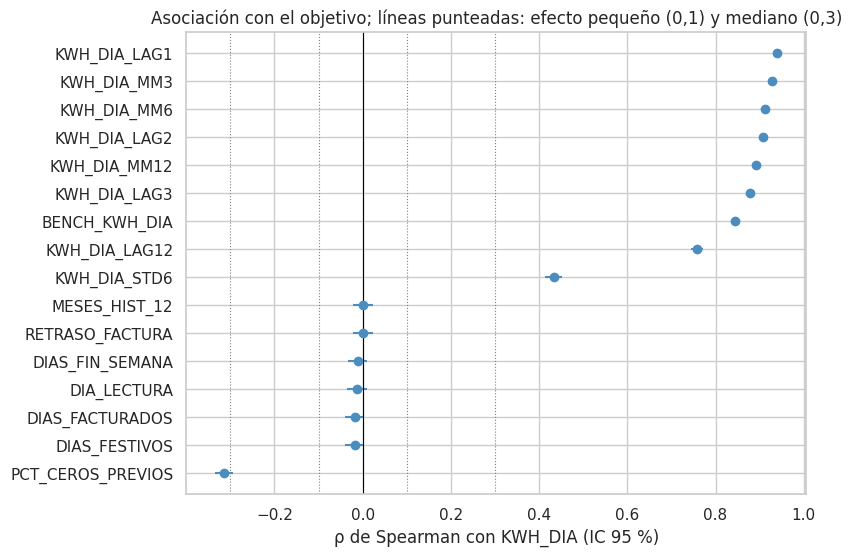

In [62]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(asoc_num['rho'], asoc_num.index, fmt='o', color='#4C8DBF',
            xerr=[asoc_num['rho'] - asoc_num['ic95_inf'], asoc_num['ic95_sup'] - asoc_num['rho']])
for v in [-0.1, 0.1, -0.3, 0.3]:
    ax.axvline(v, color='grey', ls=':', lw=0.8)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('ρ de Spearman con KWH_DIA (IC 95 %)')
ax.set_title('Asociación con el objetivo; líneas punteadas: efecto pequeño (0,1) y mediano (0,3)')
guardar_figura(fig, '05_asociacion_objetivo')
plt.show()

### 7.3 Asociación de las variables categóricas con el objetivo (ε² de Kruskal–Wallis)

In [63]:
cols_cat_eval = ['ESTRATO_SECTOR', 'TIPO_MEDIDOR', 'MES', 'MES_CONSUMO', 'DIA_LECTURA']
asoc_cat = pd.DataFrame({c: kruskal_epsilon(indep, c) for c in cols_cat_eval}).T
asoc_cat.sort_values('epsilon2', ascending=False)

,grupos,n,H,p_valor,epsilon2
ESTRATO_SECTOR,6.0000,"8,876.0000",98.8926,0.0000,0.0111
TIPO_MEDIDOR,4.0000,"8,876.0000",77.4031,0.0000,0.0087
DIA_LECTURA,31.0000,"8,876.0000",45.0047,0.0386,0.0051
MES,12.0000,"8,876.0000",20.9508,0.0339,0.0024
MES_CONSUMO,12.0000,"8,876.0000",16.7362,0.1159,0.0019


**Análisis.** `ESTRATO_SECTOR` ε² = 0,0111 (efecto pequeño, apenas sobre 0,01); `TIPO_MEDIDOR` 0,0087; `DIA_LECTURA` 0,0051 (p = 0,039);
`MES` 0,0024 (p = 0,034); `MES_CONSUMO` 0,0019 (p = 0,12). Salvo el estrato, todas están por debajo de un efecto pequeño.
Entre usuarios, la dispersión dentro de cada estrato es grande frente a las diferencias entre estratos (gráfica: medianas entre ≈ 3,5 y
≈ 5,1 kWh/día). No se detecta estacionalidad marginal entre usuarios; esto no descarta estacionalidad dentro de cada usuario, que no se midió.

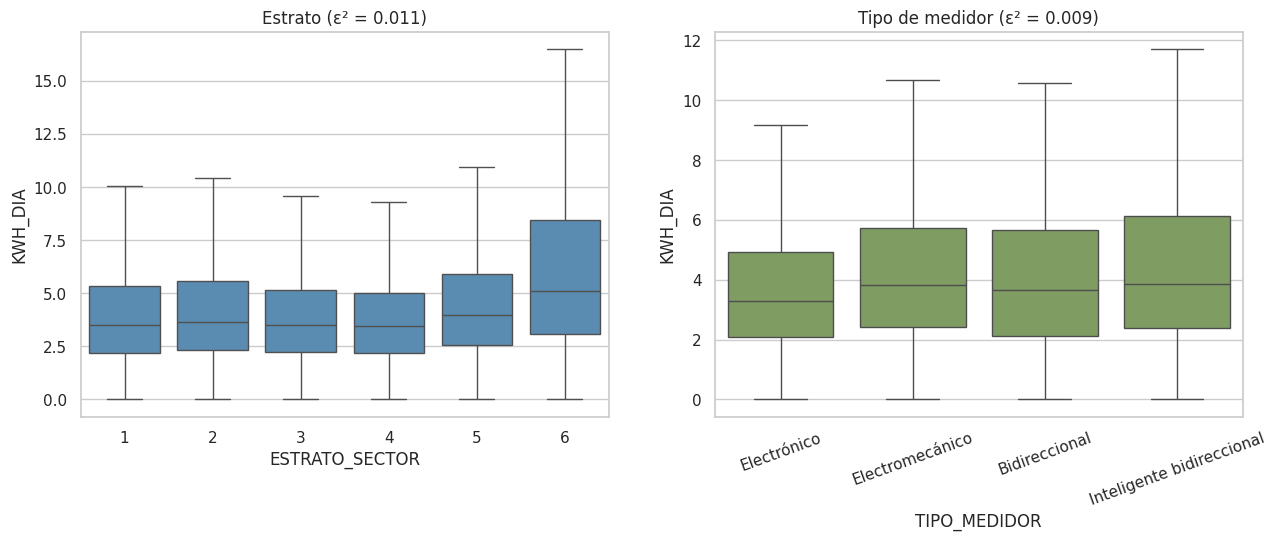

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=muestra, x='ESTRATO_SECTOR', y='KWH_DIA', showfliers=False, color='#4C8DBF', ax=axes[0])
sns.boxplot(data=muestra, x='TIPO_MEDIDOR', y='KWH_DIA', showfliers=False, color='#7FA65A', ax=axes[1])
axes[0].set_title(f"Estrato (ε² = {asoc_cat.loc['ESTRATO_SECTOR', 'epsilon2']:.3f})")
axes[1].set_title(f"Tipo de medidor (ε² = {asoc_cat.loc['TIPO_MEDIDOR', 'epsilon2']:.3f})")
axes[1].tick_params(axis='x', rotation=20)
guardar_figura(fig, '06_consumo_estrato_medidor')
plt.show()

### 7.4 Consumo del mes anterior frente al consumo actual

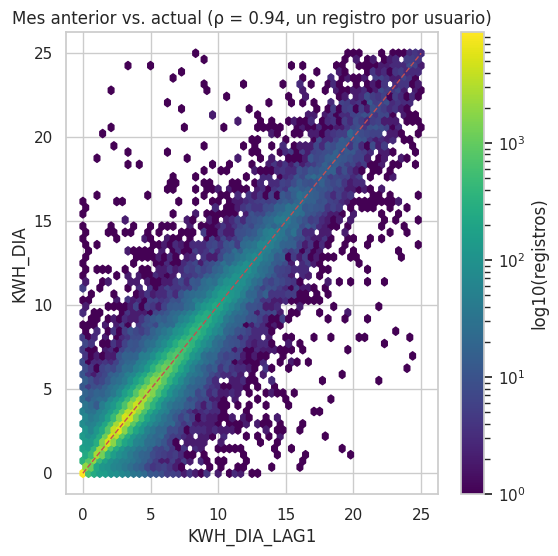

In [65]:
rho_lag1 = asoc_num.loc['KWH_DIA_LAG1', 'rho']
fig, ax = plt.subplots(figsize=(6, 6))
hb = ax.hexbin(muestra['KWH_DIA_LAG1'], muestra['KWH_DIA'], gridsize=60, extent=(0, 25, 0, 25),
               bins='log', cmap='viridis', mincnt=1)
ax.plot([0, 25], [0, 25], 'r--', lw=1)
ax.set_xlabel('KWH_DIA_LAG1'); ax.set_ylabel('KWH_DIA')
ax.set_title(f'Mes anterior vs. actual (ρ = {rho_lag1:.2f}, un registro por usuario)')
fig.colorbar(hb, label='log10(registros)')
guardar_figura(fig, '07_lag1_vs_objetivo')
plt.show()

**Análisis (descriptivo).** La densidad se concentra sobre la diagonal $y = x$ (ρ = 0,940 con un registro por usuario).

### 7.5 Perfil mensual del consumo por estrato (descriptivo)

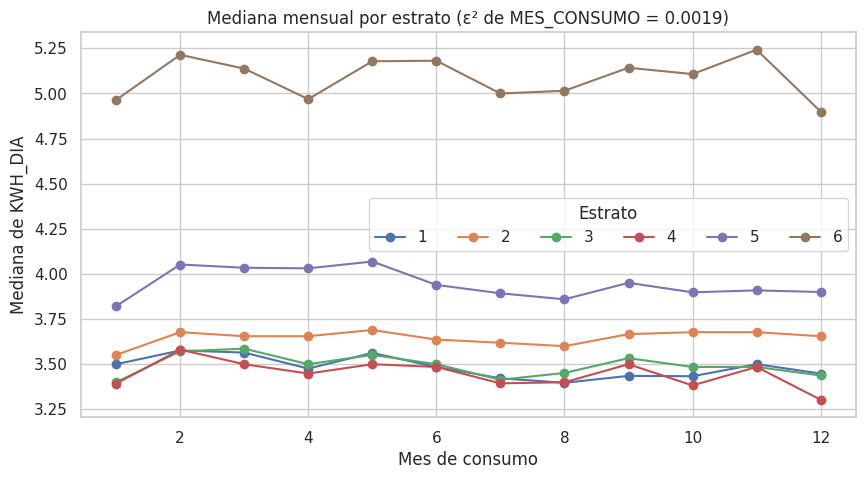

In [66]:
perfil = muestra.groupby(['MES_CONSUMO', 'ESTRATO_SECTOR'])['KWH_DIA'].median().unstack()
fig, ax = plt.subplots(figsize=(10, 5))
perfil.plot(ax=ax, marker='o')
ax.set_xlabel('Mes de consumo'); ax.set_ylabel('Mediana de KWH_DIA')
ax.set_title(f"Mediana mensual por estrato (ε² de MES_CONSUMO = {asoc_cat.loc['MES_CONSUMO', 'epsilon2']:.4f})")
ax.legend(title='Estrato', ncol=6)
guardar_figura(fig, '08_perfil_mensual_estrato')
plt.show()

**Análisis (descriptivo).** Dentro de cada estrato, la mediana mensual varía entre 0,2 y 0,3 kWh/día, sin un patrón común entre estratos;
es coherente con el ε² de `MES_CONSUMO` (0,0019, no significativo). Muestra de 2022–2023.

### 7.6 Meses previos en cero y consumo actual

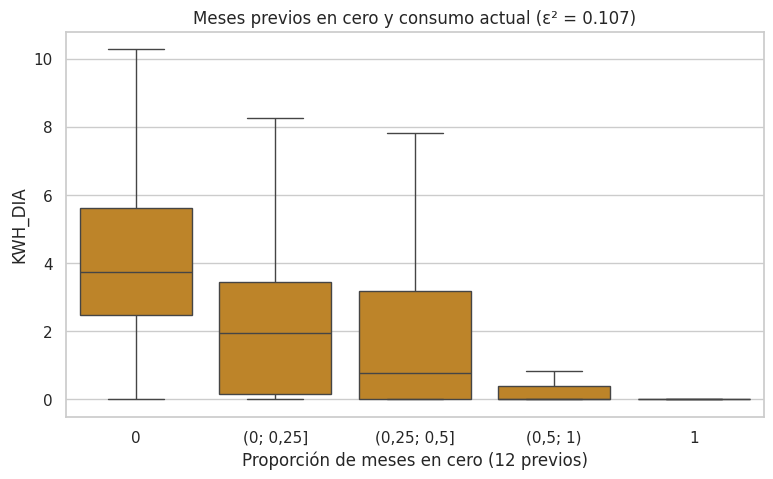

In [67]:
indep['GRUPO_CEROS'] = pd.cut(indep['PCT_CEROS_PREVIOS'], [-0.01, 0, 0.25, 0.5, 0.99, 1],
                              labels=['0', '(0; 0,25]', '(0,25; 0,5]', '(0,5; 1)', '1'])
eps_ceros = kruskal_epsilon(indep, 'GRUPO_CEROS')['epsilon2']
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=indep, x='GRUPO_CEROS', y='KWH_DIA', showfliers=False, color='#D68910', ax=ax)
ax.set_xlabel('Proporción de meses en cero (12 previos)'); ax.set_ylabel('KWH_DIA')
ax.set_title(f'Meses previos en cero y consumo actual (ε² = {eps_ceros:.3f})')
guardar_figura(fig, '09_ceros_previos')
plt.show()

**Análisis.** La proporción de meses previos en cero tiene asociación mediana con el consumo actual (ε² = 0,107). La mediana baja de
≈ 3,7 kWh/día (ningún mes en cero) a 0 (los 12 meses en cero).

### 7.7 Usuarios por transformador (último mes disponible)

In [68]:
periodo_txt = df['PERIODO'].astype(str)
ultimo = periodo_txt.max().compute()
usuarios_trafo = df[periodo_txt == ultimo]['COD_TRANSFORMADOR'].value_counts().compute()
usuarios_trafo.describe()

,count
count,"35,306.0000"
mean,67.5637
std,91.5203
min,1.0000
25%,10.0000
50%,40.0000
75%,97.0000
max,"6,295.0000"


**Análisis.** En el último mes hay 35.306 transformadores con usuarios; mediana 40 usuarios (Q1 = 10; Q3 = 97) y máximo 6.295.
Ese máximo es atípico y debe verificarse (por ejemplo, si es un código genérico).

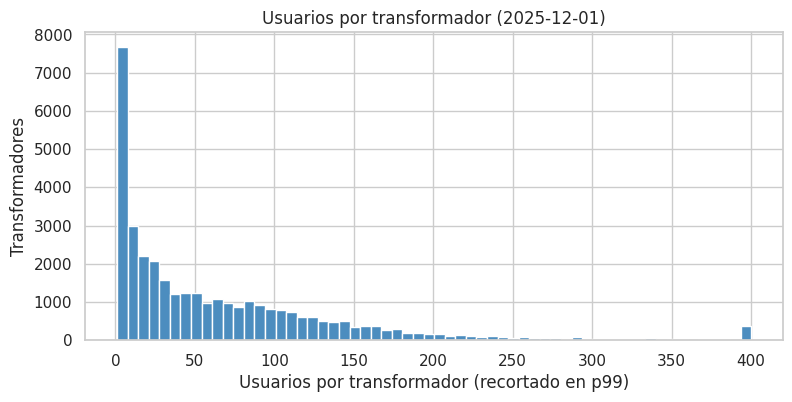

In [69]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(usuarios_trafo.clip(upper=usuarios_trafo.quantile(0.99)), bins=60, color='#4C8DBF')
ax.set_xlabel('Usuarios por transformador (recortado en p99)'); ax.set_ylabel('Transformadores')
ax.set_title(f'Usuarios por transformador ({ultimo})')
guardar_figura(fig, '10_usuarios_transformador')
plt.show()

### 7.8 Variables de calendario

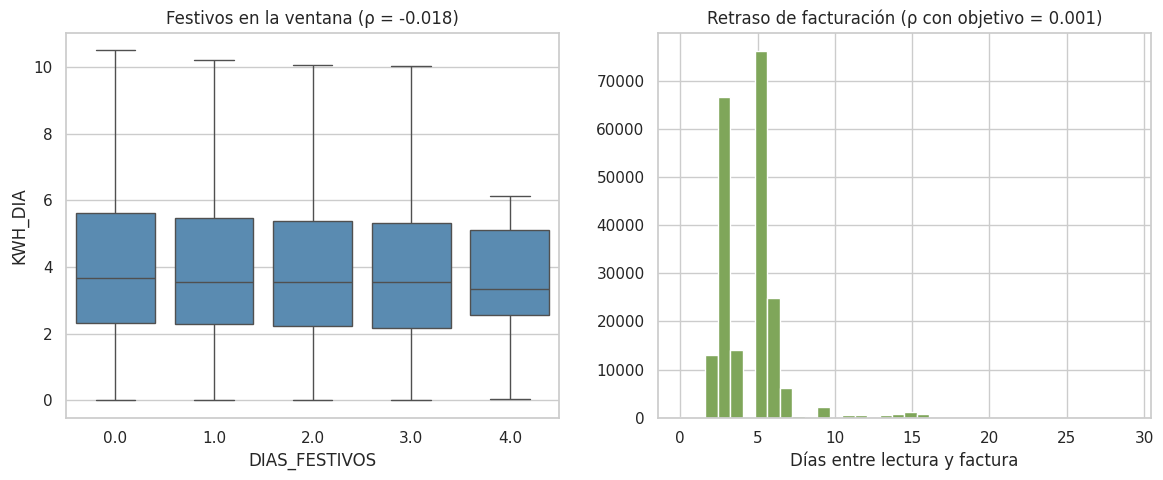

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=indep, x='DIAS_FESTIVOS', y='KWH_DIA', showfliers=False, color='#4C8DBF', ax=axes[0])
axes[0].set_title(f"Festivos en la ventana (ρ = {asoc_num.loc['DIAS_FESTIVOS', 'rho']:.3f})")
axes[1].hist(muestra['RETRASO_FACTURA'].clip(-5, 30), bins=36, color='#7FA65A')
axes[1].set_title(f"Retraso de facturación (ρ con objetivo = {asoc_num.loc['RETRASO_FACTURA', 'rho']:.3f})")
axes[1].set_xlabel('Días entre lectura y factura')
guardar_figura(fig, '11_calendario')
plt.show()

**Análisis.** La mediana de consumo es similar con 0 a 4 festivos en la ventana (ρ = −0,018). El retraso de facturación se concentra
en 2–3 y 5–6 días, con casos aislados hasta ~16 días, y no se asocia con el consumo (ρ = 0,001).

## 8. Reducción y agrupación de variables
Esta sección **no usa el objetivo**: la redundancia se mide solo entre características.
La selección por relevancia predictiva se hará en el modelado, dentro del entrenamiento.

### 8.1 Dimensionalidad del bloque de consumo histórico (PCA)

In [71]:
bloque = indep[cols_consumo + ['KWH_DIA_STD6']].dropna()
pca = PCA().fit(StandardScaler().fit_transform(bloque))
var_acum = np.cumsum(pca.explained_variance_ratio_)
pd.DataFrame({'varianza': pca.explained_variance_ratio_, 'acumulada': var_acum},
             index=[f'CP{i + 1}' for i in range(len(var_acum))])

,varianza,acumulada
CP1,0.8522,0.8522
CP2,0.1005,0.9527
CP3,0.0315,0.9842
CP4,0.0079,0.9921
CP5,0.0041,0.9961
CP6,0.0033,0.9995
CP7,0.0005,1.0000
CP8,0.0000,1.0000


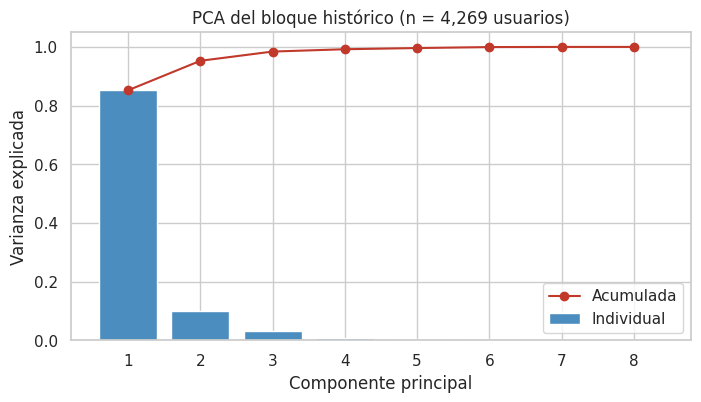

In [72]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(1, len(var_acum) + 1)
ax.bar(x, pca.explained_variance_ratio_, color='#4C8DBF', label='Individual')
ax.plot(x, var_acum, 'o-', color='#C0392B', label='Acumulada')
ax.set_xlabel('Componente principal'); ax.set_ylabel('Varianza explicada')
ax.set_title(f'PCA del bloque histórico (n = {len(bloque):,} usuarios)'); ax.legend()
guardar_figura(fig, '12_pca_consumo')
plt.show()

In [73]:
pd.DataFrame(pca.components_[:3].T, index=bloque.columns, columns=['CP1', 'CP2', 'CP3']).round(3)

,CP1,CP2,CP3
KWH_DIA_LAG1,0.3720,-0.0750,-0.2170
KWH_DIA_LAG2,0.3740,-0.0820,-0.2640
KWH_DIA_LAG3,0.3730,-0.0940,-0.1920
KWH_DIA_LAG12,0.3450,-0.0310,0.8550
KWH_DIA_MM3,0.3790,-0.0850,-0.2280
KWH_DIA_MM6,0.3800,-0.0580,-0.0930
KWH_DIA_MM12,0.3780,-0.0520,0.2280
KWH_DIA_STD6,0.1810,0.9820,-0.0430


**Análisis.** CP1 explica el 85,2 % de la varianza del bloque histórico con cargas similares (0,35–0,38): componente de **nivel**.
CP2 (10,1 %) carga en `KWH_DIA_STD6` (0,982): **volatilidad**. CP3 (3,2 %) carga en `KWH_DIA_LAG12` (0,855): **componente anual**.
Tres componentes explican el 98,4 %.

### 8.2 Variables agrupadas
Transformaciones deterministas del bloque histórico (no se estiman con los datos):

| Variable | Fórmula |
|---|---|
| `NIVEL_12` | `KWH_DIA_MM12` |
| `TENDENCIA` | `KWH_DIA_MM3 − KWH_DIA_MM12` |
| `ESTACIONAL` | `KWH_DIA_LAG12 − KWH_DIA_MM12` |
| `CV6` | `KWH_DIA_STD6 / KWH_DIA_MM6` (si `KWH_DIA_MM6 > 0`) |

In [74]:
def agrupar(d):
    return d.assign(NIVEL_12=d['KWH_DIA_MM12'],
                    TENDENCIA=d['KWH_DIA_MM3'] - d['KWH_DIA_MM12'],
                    ESTACIONAL=d['KWH_DIA_LAG12'] - d['KWH_DIA_MM12'],
                    CV6=(d['KWH_DIA_STD6'] / d['KWH_DIA_MM6']).where(d['KWH_DIA_MM6'] > 0))

df, indep = agrupar(df), agrupar(indep)

### 8.3 Redundancia por agrupamiento jerárquico
**Método:** distancia $1 - |\rho|$ y enlace completo; con corte en $1 -$ `UMBRAL_REDUNDANCIA`, dentro de cada grupo
**todas** las parejas tienen $|\rho| \geq$ `UMBRAL_REDUNDANCIA`.
**Representante de cada grupo:** la variable con menos valores nulos; en empate, la que aparece primero en `candidatas`
(ordenadas de más a menos interpretable). No se usa el objetivo.

In [75]:
candidatas = ['KWH_DIA_LAG1', 'KWH_DIA_LAG12', 'NIVEL_12', 'TENDENCIA', 'ESTACIONAL', 'CV6', 'KWH_DIA_STD6',
              'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_LAG2', 'KWH_DIA_LAG3', 'PCT_CEROS_PREVIOS',
              'MESES_HIST_12', 'DIAS_FACTURADOS'] + cols_calendario
candidatas += [c for c in ['NRO_FAMILIAS', 'MESES_DESDE_CAMBIO'] if c in df.columns]
dist = 1 - indep[candidatas].corr(method='spearman').abs().fillna(0).to_numpy(copy=True)
np.fill_diagonal(dist, 0)
Z = linkage(squareform(dist, checks=False), method='complete')
grupo = pd.Series(fcluster(Z, t=1 - UMBRAL_REDUNDANCIA, criterion='distance'), index=candidatas)

In [76]:
nulos = indep[candidatas].isnull().mean()
orden = pd.Series(range(len(candidatas)), index=candidatas)
tabla_red = pd.DataFrame({'grupo': grupo, '% nulos': nulos * 100, 'orden': orden})
representantes = tabla_red.sort_values(['% nulos', 'orden']).groupby('grupo').head(1).index
tabla_red['seleccionada'] = tabla_red.index.isin(representantes)
tabla_red.sort_values(['grupo', 'orden'])

,grupo,% nulos,orden,seleccionada
MESES_HIST_12,1,0.0000,12,True
MESES_DESDE_CAMBIO,2,8.4160,18,True
DIAS_FACTURADOS,3,0.0000,13,True
DIAS_FIN_SEMANA,4,0.0000,15,True
DIAS_FESTIVOS,5,0.0000,16,True
DIA_LECTURA,6,0.0000,14,True
CV6,7,10.8720,5,True
KWH_DIA_STD6,8,9.4525,6,True
KWH_DIA_MM3,9,4.9910,7,True
KWH_DIA_LAG2,9,9.5088,9,False


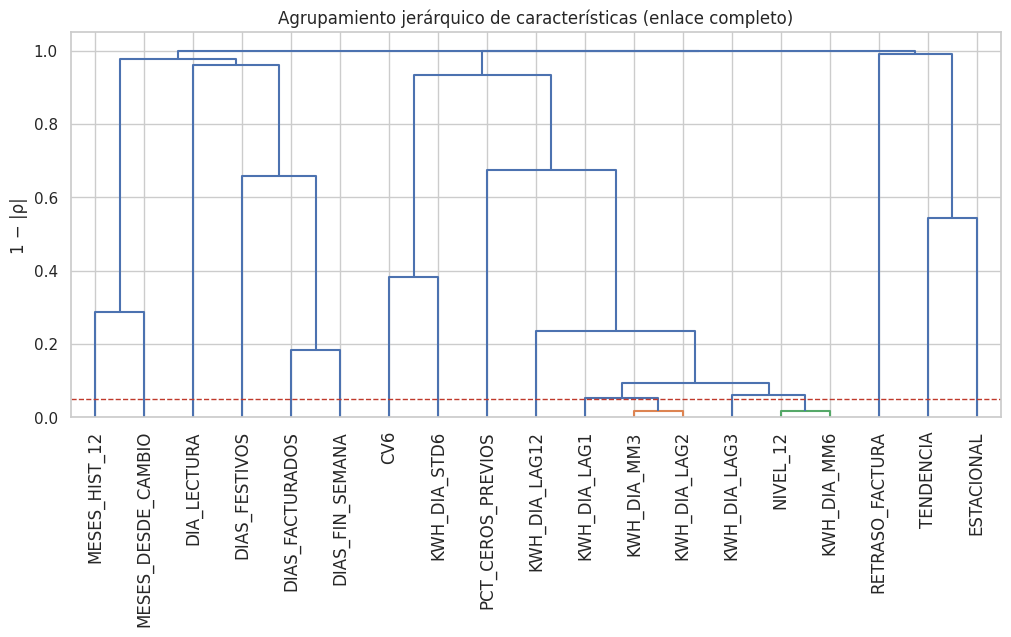

In [77]:
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z, labels=candidatas, leaf_rotation=90, ax=ax, color_threshold=1 - UMBRAL_REDUNDANCIA)
ax.axhline(1 - UMBRAL_REDUNDANCIA, color='#C0392B', ls='--', lw=1)
ax.set_ylabel('1 − |ρ|'); ax.set_title('Agrupamiento jerárquico de características (enlace completo)')
guardar_figura(fig, '13_dendrograma_redundancia')
plt.show()

In [78]:
sensibilidad = {u: fcluster(Z, t=1 - u, criterion='distance').max() for u in [0.80, 0.85, 0.90, 0.95, 0.99]}
pd.Series(sensibilidad, name='variables resultantes').rename_axis('umbral |ρ|')

,variables resultantes
umbral |ρ|,
0.8000,13
0.8500,14
0.9000,14
0.9500,17
0.9900,19


In [79]:
seleccion_num = [c for c in candidatas if c in representantes]
print('Seleccionadas:', seleccion_num)

Seleccionadas: ['KWH_DIA_LAG1', 'KWH_DIA_LAG12', 'TENDENCIA', 'ESTACIONAL', 'CV6', 'KWH_DIA_STD6', 'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_LAG3', 'PCT_CEROS_PREVIOS', 'MESES_HIST_12', 'DIAS_FACTURADOS', 'DIA_LECTURA', 'DIAS_FIN_SEMANA', 'DIAS_FESTIVOS', 'RETRASO_FACTURA', 'MESES_DESDE_CAMBIO']


**Análisis.** Con |ρ| ≥ 0,95 se fusionan dos parejas: `KWH_DIA_MM3`–`KWH_DIA_LAG2` (se conserva `KWH_DIA_MM3`, menos nulos) y
`NIVEL_12`–`KWH_DIA_MM6` (se conserva `KWH_DIA_MM6`: 4,98 % de nulos frente a 5,00 %; la diferencia es mínima).
Quedan 17 características numéricas. Sensibilidad: 13 variables con 0,80; 14 con 0,85–0,90; 17 con 0,95; 19 con 0,99.

`KWH_DIA_LAG12` y `ESTACIONAL` tienen 51,8 % de nulos en la muestra porque 2022 no tiene rezago anual. Si se usan, el entrenamiento
debería empezar en 2023.

## 9. Conjunto final y exportación
Llaves, objetivo, línea base, categóricas y numéricas seleccionadas. Se guarda en Parquet, particionado por año.

In [80]:
cols_categoricas = ['ESTRATO_SECTOR', 'TIPO_MEDIDOR', 'MES', 'MES_CONSUMO', 'COD_TRANSFORMADOR', 'COD_CIRCUITO_LINEA']
cols_categoricas += [c for c in ['UBICACION', 'CAMBIO_TRAFO', 'CAMBIO_ESTRATO', 'CAMBIO_MEDIDOR'] if c in df.columns]
cols_finales = ['PERIODO', 'NIU_USUARIO', 'KWH_DIA', 'BENCH_KWH_DIA', 'PROM_SEM_BENCHMARK', 'BENCH_VALIDO'] \
               + cols_categoricas + seleccion_num
df = df[cols_finales]
pd.DataFrame({'columna': cols_finales})

,columna
0,PERIODO
1,NIU_USUARIO
2,KWH_DIA
3,BENCH_KWH_DIA
4,PROM_SEM_BENCHMARK
5,BENCH_VALIDO
6,ESTRATO_SECTOR
7,TIPO_MEDIDOR
8,MES
9,MES_CONSUMO


In [81]:
df['ANIO'] = dd.to_datetime(df['PERIODO']).dt.year
df.to_parquet(DRIVE_SALIDA, partition_on=['ANIO'], write_index=False, overwrite=True)
final = dd.read_parquet(DRIVE_SALIDA)
print(f'Registros: {len(final):,} | Columnas: {len(final.columns)}')

Registros: 109,020,828 | Columnas: 30


**Análisis.** Se exportaron 109.020.828 registros y 30 columnas (incluida `ANIO`) a `dataset_modelo_prep`.

## 10. Conclusiones de la preparación (ejecución del 7 de octubre de 2026)

### Resultados medidos
1. **Limpieza:** se conservan 109.020.828 registros (99,70 %). Con cuartiles exactos, el filtro de días elimina 55.136 registros, sin concentración en ningún mes (máximo 0,07 %).
2. **Atípicos del objetivo:** límite de 48,90 kWh/día (Tukey k = 3 sobre log), 262.740 registros (0,24 %).
3. **Cuantiles:** los cuartiles aproximados de Dask del notebook 1 no son confiables (`KWH_DIA`: 2,52/6,28 frente a 2,22/5,39 exactos). Se retiraron del trabajo de grado; los únicos cuartiles reportados son los exactos de este notebook.
4. **Columnas eliminadas (15):** 5 de varianza nula, 5 de varianza casi nula sin efecto, `CONS_SUBSIST` (redundante con el estrato, V = 0,683) y 4 con fuga de información por definición.
5. **`TIPO_MEDIDOR` no oscila:** solo el 0,15 % de los cambios se revierte.
6. **Asociación con el objetivo:** la historia de consumo, grande (ρ entre 0,76 y 0,94); `PCT_CEROS_PREVIOS` y la volatilidad, mediana; el estrato, pequeña (ε² = 0,011); el calendario y el mes, menor que pequeña.
7. **Redundancia:** el bloque histórico tiene tres dimensiones dominantes (98,4 % de la varianza). Con |ρ| ≥ 0,95 quedan 17 características numéricas.
8. **Conjunto final:** `dataset_modelo_prep`, 109.020.828 registros y 30 columnas.

### Acciones pendientes
1. Probar si las variables de calendario se asocian con la **desviación** del consumo respecto a la historia del usuario (solo con datos de entrenamiento).
2. Verificar el transformador con 6.295 usuarios.
3. Definir la partición temporal con prueba y validación posteriores a 2023.

### Supuestos no verificados con estos datos
1. La fecha real de lectura aproxima la fecha planeada del cronograma (sección 5).
2. La muestra por prefijo del hash es pseudoaleatoria; solo se contrastó por estrato.
3. Las convenciones de umbrales (Tukey, Kuhn y Johnson, Cohen) son adecuadas; se reporta su sensibilidad.
